# 08 — Umbrales y capacidad de atención

Objetivos:
- Analizar el equilibrio entre precisión, recall y falsas alertas.
- Comparar modelos con distintos umbrales.
- Comparar cuántos positivos detectan para una misma cantidad de contactos.

Se utilizan las predicciones temporales de 2023 guardadas en el notebook 07.
No se vuelve a entrenar, no se recalculan features ni se modifica el target.

Ejecutar todas las celdas en orden desde un kernel nuevo.

**Alcance:** este análisis es exploratorio. Cambiar el corte modifica las alertas, pero no mejora ROC-AUC ni Average Precision. Las capacidades son ejemplos, no límites confirmados por Psicología. No se fija todavía un umbral definitivo ni se presenta 2023 como test independiente.


## 1. Entorno y rutas

Se utilizan pandas, NumPy y Matplotlib. Este cuaderno no necesita cargar LightGBM ni el modelo entrenado.


In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

PROJ_ROOT = Path.cwd()

if PROJ_ROOT.name == "notebooks":
    PROJ_ROOT = PROJ_ROOT.parent

assert (PROJ_ROOT / "src").is_dir(), (
    f"No se encontró la raíz del proyecto desde {PROJ_ROOT}"
)

os.chdir(PROJ_ROOT)

CLAVES = ["id_alumno", "anio_academico"]
RUTA_PREDICCIONES = PROJ_ROOT / "reports" / "predicciones_temporales.csv"
CARPETA_REPORTES = PROJ_ROOT / "reports"

print("Proyecto:", PROJ_ROOT)
print("Predicciones:", RUTA_PREDICCIONES)


Proyecto: /Users/alejo/Desktop/alerta-temprana-desercion
Predicciones: /Users/alejo/Desktop/alerta-temprana-desercion/reports/predicciones_temporales.csv


## 2. Carga y validación de las predicciones

Se comprueba que todos los modelos evalúen los mismos estudiantes, con las mismas etiquetas y particiones, en un único año. Con los resultados actuales se esperan 589 estudiantes y 152 positivos por modelo.


In [2]:
assert RUTA_PREDICCIONES.is_file(), (
    "Primero ejecutá y guardá los resultados del notebook 07."
)

predicciones = pd.read_csv(RUTA_PREDICCIONES)

requeridas = {
    "modelo",
    "id_alumno",
    "anio_academico",
    "fold",
    "abandono_real",
    "probabilidad_abandono",
}

assert requeridas.issubset(predicciones.columns)
assert not predicciones.empty
assert predicciones[list(requeridas)].notna().all().all()

assert not predicciones.duplicated(["modelo"] + CLAVES).any()
assert predicciones["abandono_real"].isin([0, 1]).all()
assert predicciones["probabilidad_abandono"].between(0, 1).all()
assert predicciones["anio_academico"].nunique() == 1

cantidad_modelos = predicciones["modelo"].nunique()

assert predicciones.groupby(CLAVES)["modelo"].nunique().eq(
    cantidad_modelos
).all()

assert predicciones.groupby(CLAVES)["abandono_real"].nunique().eq(1).all()
assert predicciones.groupby(CLAVES)["fold"].nunique().eq(1).all()

poblacion = predicciones.drop_duplicates(CLAVES)
assert poblacion["id_alumno"].is_unique

ANIO_EVALUADO = int(poblacion["anio_academico"].iloc[0])
PREVALENCIA = poblacion["abandono_real"].mean()

print("Año evaluado:", ANIO_EVALUADO)
print("Estudiantes:", len(poblacion))
print("Positivos:", int(poblacion["abandono_real"].sum()))
print(f"Proporción de positivos: {PREVALENCIA:.2%}")

display(
    predicciones.groupby("modelo").agg(
        estudiantes=("id_alumno", "nunique"),
        positivos=("abandono_real", "sum"),
    )
)


Año evaluado: 2023
Estudiantes: 589
Positivos: 152
Proporción de positivos: 25.81%


,estudiantes,positivos
modelo,,
lightgbm_anio,589,152
lightgbm_base,589,152
logistica_base,589,152


## 3. Función para evaluar las alertas

Precisión: proporción de alertas que son positivas. Recall: proporción de positivos detectados. Ambas se muestran entre 0 y 1. Si no se emiten alertas, se registra precisión cero por convención.


In [3]:
def resumir_decisiones(grupo, alertas):
    real = grupo["abandono_real"].to_numpy(dtype=int)
    alertas = np.asarray(alertas, dtype=bool)

    assert alertas.ndim == 1
    assert len(real) == len(alertas)

    positivos = real == 1

    tp = int((positivos & alertas).sum())
    fp = int((~positivos & alertas).sum())
    fn = int((positivos & ~alertas).sum())
    tn = int((~positivos & ~alertas).sum())

    return {
        "estudiantes": len(real),
        "positivos": int(positivos.sum()),
        "alertas": int(alertas.sum()),
        "porcentaje_alertas": 100 * alertas.mean(),
        "verdaderos_positivos": tp,
        "falsos_positivos": fp,
        "falsos_negativos": fn,
        "verdaderos_negativos": tn,
        "precision": tp / (tp + fp) if tp + fp else 0.0,
        "recall": tp / (tp + fn) if tp + fn else np.nan,
    }


## 4. Evaluación de distintos umbrales

Se recorre una grilla de cortes de 0 a 1. Solo cambia la decisión de emitir una alerta; las probabilidades permanecen iguales.


In [4]:
UMBRALES = np.round(np.linspace(0, 1, 101), 2)

filas = []

for modelo, grupo in predicciones.groupby("modelo"):
    for umbral in UMBRALES:
        alertas = grupo["probabilidad_abandono"].ge(umbral)

        filas.append({
            "modelo": modelo,
            "umbral": umbral,
            **resumir_decisiones(grupo, alertas),
        })

tabla_umbrales = pd.DataFrame(filas)

assert len(tabla_umbrales) == cantidad_modelos * len(UMBRALES)

print("Escenarios evaluados:", len(tabla_umbrales))


Escenarios evaluados: 303


## 5. Revisión de cortes concretos

Comparar cuántos positivos adicionales se detectan al bajar el corte y cuántas falsas alertas se agregan. Un recall alto obtenido alertando a casi todos no implica un sistema útil.


In [5]:
cortes_revision = [0.50, 0.40, 0.30, 0.20, 0.10]

columnas_revision = [
    "modelo",
    "umbral",
    "alertas",
    "verdaderos_positivos",
    "falsos_positivos",
    "falsos_negativos",
    "precision",
    "recall",
]

display(
    tabla_umbrales.loc[
        tabla_umbrales["umbral"].isin(cortes_revision),
        columnas_revision,
    ]
    .sort_values(["modelo", "umbral"], ascending=[True, False])
    .round(4)
)


,modelo,umbral,alertas,verdaderos_positivos,falsos_positivos,falsos_negativos,precision,recall
50,lightgbm_anio,0.5,91,60,31,92,0.6593,0.3947
40,lightgbm_anio,0.4,122,67,55,85,0.5492,0.4408
30,lightgbm_anio,0.3,148,80,68,72,0.5405,0.5263
20,lightgbm_anio,0.2,199,93,106,59,0.4673,0.6118
10,lightgbm_anio,0.1,297,115,182,37,0.3872,0.7566
151,lightgbm_base,0.5,92,59,33,93,0.6413,0.3882
141,lightgbm_base,0.4,115,67,48,85,0.5826,0.4408
131,lightgbm_base,0.3,154,73,81,79,0.4740,0.4803
121,lightgbm_base,0.2,203,86,117,66,0.4236,0.5658
111,lightgbm_base,0.1,298,106,192,46,0.3557,0.6974


## 6. Visualización del efecto del corte

La línea vertical marca el corte inicial de 0,50. Cada gráfico muestra una consecuencia diferente de cambiar la decisión de alerta.


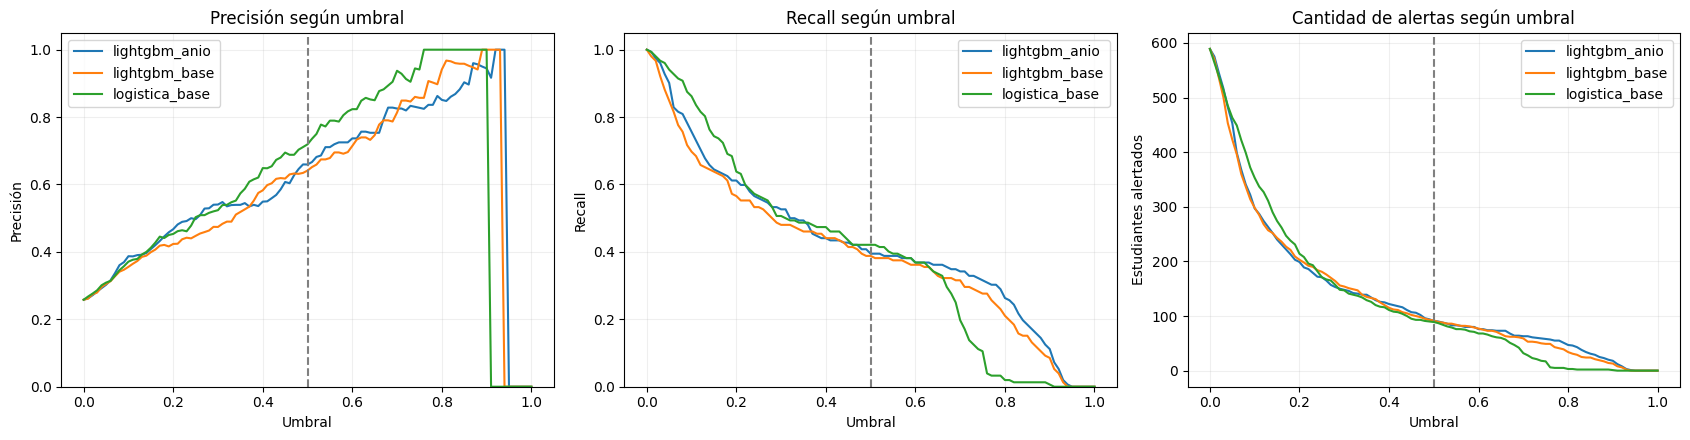

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

for modelo, grupo in tabla_umbrales.groupby("modelo"):
    axes[0].plot(grupo["umbral"], grupo["precision"], label=modelo)
    axes[1].plot(grupo["umbral"], grupo["recall"], label=modelo)
    axes[2].plot(grupo["umbral"], grupo["alertas"], label=modelo)

titulos = [
    "Precisión según umbral",
    "Recall según umbral",
    "Cantidad de alertas según umbral",
]

for ax, titulo in zip(axes, titulos):
    ax.set_title(titulo)
    ax.set_xlabel("Umbral")
    ax.axvline(0.50, color="gray", linestyle="--")
    ax.grid(alpha=0.2)
    ax.legend()

axes[0].set_ylim(0, 1.05)
axes[0].set_ylabel("Precisión")
axes[1].set_ylim(0, 1.05)
axes[1].set_ylabel("Recall")
axes[2].set_ylabel("Estudiantes alertados")

plt.tight_layout()
plt.show()


## 7. Comparación con una misma capacidad de atención

Se seleccionan los K estudiantes con mayor puntuación de cada modelo. Las capacidades son escenarios ilustrativos. Ante empates, se ordena por identificador para reproducir el cálculo; no es una política institucional. El score mínimo seleccionado no siempre equivale a un umbral que produzca exactamente K alertas si hay empates.


In [7]:
CAPACIDADES = [50, 100, 150, 200, 250, 300]

filas = []

for modelo, grupo in predicciones.groupby("modelo"):
    ranking = grupo.sort_values(
        ["probabilidad_abandono", "id_alumno"],
        ascending=[False, True],
    )

    for capacidad in CAPACIDADES:
        cantidad = min(capacidad, len(ranking))
        alertas = np.arange(len(ranking)) < cantidad

        seleccionados = ranking.iloc[:cantidad]
        score_corte = seleccionados["probabilidad_abandono"].iloc[-1]

        empate_en_limite = (
            ranking["probabilidad_abandono"].eq(score_corte).sum()
            > seleccionados["probabilidad_abandono"].eq(score_corte).sum()
        )

        filas.append({
            "modelo": modelo,
            "capacidad": capacidad,
            "score_minimo_seleccionado": score_corte,
            "empate_en_limite": bool(empate_en_limite),
            **resumir_decisiones(ranking, alertas),
        })

tabla_capacidades = pd.DataFrame(filas)

display(
    tabla_capacidades[[
        "modelo",
        "capacidad",
        "verdaderos_positivos",
        "falsos_positivos",
        "falsos_negativos",
        "precision",
        "recall",
        "empate_en_limite",
    ]].round(4)
)


,modelo,capacidad,verdaderos_positivos,falsos_positivos,falsos_negativos,precision,recall,empate_en_limite
0,lightgbm_anio,50,43,7,109,0.8600,0.2829,False
1,lightgbm_anio,100,63,37,89,0.6300,0.4145,False
2,lightgbm_anio,150,81,69,71,0.5400,0.5329,False
3,lightgbm_anio,200,93,107,59,0.4650,0.6118,False
4,lightgbm_anio,250,100,150,52,0.4000,0.6579,False
5,lightgbm_anio,300,116,184,36,0.3867,0.7632,False
6,lightgbm_base,50,43,7,109,0.8600,0.2829,False
7,lightgbm_base,100,63,37,89,0.6300,0.4145,False
8,lightgbm_base,150,73,77,79,0.4867,0.4803,False
9,lightgbm_base,200,85,115,67,0.4250,0.5592,False


## 8. Visualización según cantidad de contactos

Se compara el desempeño con el mismo número de contactos. El modelo con mejor ROC-AUC global no necesariamente es el mejor para todas las capacidades.


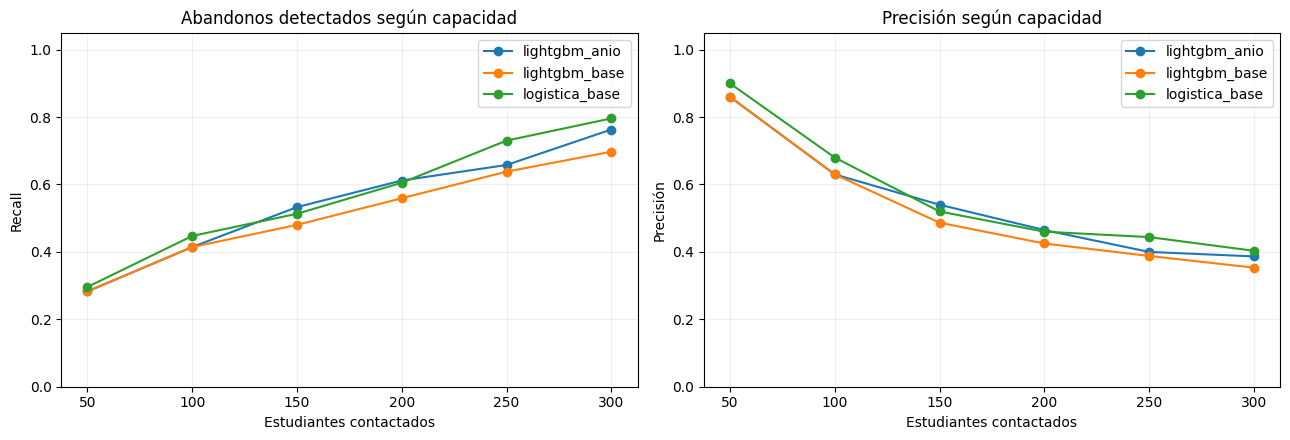

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for modelo, grupo in tabla_capacidades.groupby("modelo"):
    axes[0].plot(
        grupo["alertas"], grupo["recall"],
        marker="o", label=modelo,
    )
    axes[1].plot(
        grupo["alertas"], grupo["precision"],
        marker="o", label=modelo,
    )

axes[0].set_title("Abandonos detectados según capacidad")
axes[0].set_ylabel("Recall")
axes[1].set_title("Precisión según capacidad")
axes[1].set_ylabel("Precisión")

for ax in axes:
    ax.set_xlabel("Estudiantes contactados")
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.2)
    ax.legend()

plt.tight_layout()
plt.show()


## 9. Escenario ilustrativo de atención

Se muestran los resultados para 150 contactos. Este valor permite entender la comparación y no establece la capacidad real del departamento.


In [9]:
CAPACIDAD_EJEMPLO = 150

assert CAPACIDAD_EJEMPLO in CAPACIDADES

display(
    tabla_capacidades.loc[
        tabla_capacidades["capacidad"].eq(CAPACIDAD_EJEMPLO),
        [
            "modelo",
            "alertas",
            "verdaderos_positivos",
            "falsos_positivos",
            "falsos_negativos",
            "precision",
            "recall",
        ],
    ].round(4)
)


,modelo,alertas,verdaderos_positivos,falsos_positivos,falsos_negativos,precision,recall
2,lightgbm_anio,150,81,69,71,0.5400,0.5329
8,lightgbm_base,150,73,77,79,0.4867,0.4803
14,logistica_base,150,78,72,74,0.5200,0.5132


## 10. Variación de los resultados entre folds

Se revisan tres cortes en cada grupo de estudiantes. Las medias entre folds pueden diferir de las métricas calculadas agrupando todas las predicciones; las desviaciones estándar no son intervalos de confianza.


In [10]:
filas = []

for (modelo, fold), grupo in predicciones.groupby(["modelo", "fold"]):
    for umbral in [0.50, 0.30, 0.20]:
        alertas = grupo["probabilidad_abandono"].ge(umbral)

        filas.append({
            "modelo": modelo,
            "fold": fold,
            "umbral": umbral,
            **resumir_decisiones(grupo, alertas),
        })

umbrales_por_fold = pd.DataFrame(filas)

resumen_por_fold = (
    umbrales_por_fold
    .groupby(["modelo", "umbral"])[["precision", "recall"]]
    .agg(["mean", "std"])
)

display(resumen_por_fold.round(4))


precision          recall        
                           mean     std    mean     std
modelo         umbral                                  
lightgbm_anio  0.2       0.4632  0.0575  0.5970  0.1007
               0.3       0.5365  0.0508  0.5204  0.0871
               0.5       0.6606  0.0835  0.3953  0.0677
lightgbm_base  0.2       0.4231  0.0474  0.5645  0.0370
               0.3       0.4723  0.0448  0.4780  0.0401
               0.5       0.6382  0.0481  0.3903  0.0634
logistica_base 0.2       0.4554  0.0749  0.6295  0.0622
               0.3       0.5185  0.0622  0.5023  0.0334
               0.5       0.7164  0.1144  0.4224  0.0485

## 11. Guardado del análisis

Al ejecutar esta celda se generan tres CSV en reports/. No se modifican las predicciones originales, el dataset de modelado, los modelos ni las configuraciones.


In [11]:
CARPETA_REPORTES.mkdir(parents=True, exist_ok=True)

tabla_umbrales.to_csv(
    CARPETA_REPORTES / "analisis_umbrales.csv",
    index=False,
)

tabla_capacidades.to_csv(
    CARPETA_REPORTES / "analisis_capacidades.csv",
    index=False,
)

umbrales_por_fold.to_csv(
    CARPETA_REPORTES / "umbrales_por_fold.csv",
    index=False,
)

print("Análisis de umbrales y capacidad guardado en:", CARPETA_REPORTES)


Análisis de umbrales y capacidad guardado en: /Users/alejo/Desktop/alerta-temprana-desercion/reports


## Conclusiones del análisis operativo

Con las predicciones temporales actuales:

- **Bajar el corte aumenta la detección y las falsas alertas.** En logística, pasar de 0,50 a 0,20 eleva el recall de 42,11 % a 63,82 %, pero reduce la precisión de 71,91 % a 45,33 % y aumenta las alertas de 89 a 214.
- **La preferencia depende de la capacidad.** Para 100 contactos, la logística detecta 68 positivos y LightGBM con año 63. Para 150 contactos, LightGBM con año detecta 81 y la logística 78. Estas diferencias son descriptivas; no prueban superioridad estadística.
- **No se establece todavía un corte definitivo.** Debe acordarse cuántos estudiantes puede atender Psicología y qué equilibrio entre detección y falsas alertas resulta útil.
- **Se conserva el alcance exploratorio.** Este cuaderno no mejora las probabilidades ni la ordenación del riesgo. El año 2023 ya fue inspeccionado; cualquier regla seleccionada aquí requiere validación adicional antes de presentarse como desempeño final.

Quedan pendientes mejoras de variables, calibración, explicabilidad y evaluación de estabilidad temporal. Si cambian las predicciones de entrada, deben actualizarse estas conclusiones.
